# [실습] 회귀 — 숫자를 예측하고 오차로 말하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 2 실습. 이 집은 얼마에 팔릴까?

**필수 머신러닝 · Chapter 2**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 베이스라인 고르기 |
| Part 3 | 현행 방법 만들기: 사람의 시세 규칙 |
| Part 4 | 모델 만들기와 실험 기록 |
| Part 5 | 오차 들여다보기와 보고 |

## 분석 의뢰서

> **의뢰 부서**: 부동산 플랫폼 기획팀
> **목적**: 매물을 등록할 때 "이 집은 대략 얼마" 하는 적정 시세를 자동으로 제시하고 싶다.
> **제약**: 시세가 실제 거래가와 너무 다르면 판매자와 구매자 모두 플랫폼을 믿지 않게 된다.
> **질문**: 집의 정보로 거래가를 얼마나 정확히 예측할 수 있을까?

## 이 실습의 질문

> **기획팀에 "이 모델의 시세는 평균적으로 ±얼마"라고 말한다면, 어떤 지표로 얼마라고 말할 것인가? 그리고 그 숫자를 믿어도 되는 집과 믿으면 안 되는 집은 어떻게 다른가?**

Chapter 1과 같은 순서로 진행합니다. 여러분이 먼저 중개사처럼 **사람의 시세 규칙**을 만들고, 그 시세 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 기획팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

Kaggle의 House Prices 대회 데이터인 `train.csv`(Ames Housing, 1,460채)를 이 노트북과 같은 폴더에 두세요.

In [65]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

강의에서는 피처 다섯 개만 썼습니다. 여기서는 데이터에 실제로 어떤 문제가 들어 있는지 직접 확인하고, 그 문제를 어떻게 다룰지 스스로 정합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** `train.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 쓰세요. 열이 많아서 `df.head()`는 일부만 보입니다.
</details>

In [66]:
# 캐글 로그인 - API 키 생성 후 로그인
# import kagglehub

# kagglehub.login()

In [67]:
# 데이터 불러오기
path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

print("Path to competition files:", path)

Path to competition files: C:\Users\jihun\.cache\kagglehub\competitions\house-prices-advanced-regression-techniques


In [68]:
import os

print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "train.csv"))

print(df.shape)  # 행, 열 수
df.head()


['data_description.txt', 'sample_submission.csv', 'test.csv', 'train.csv']
(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1-2. 거래가 살펴보기

**[직접 작성]** 거래가(`SalePrice`)의 평균, 중앙값, 최솟값, 최댓값을 확인하세요.

<details><summary>힌트</summary>

`df["SalePrice"].describe()`가 한 번에 보여 줍니다. 중앙값은 `50%` 줄입니다.
</details>

In [69]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

**[제공]** 거래가의 분포를 그려 봅니다.

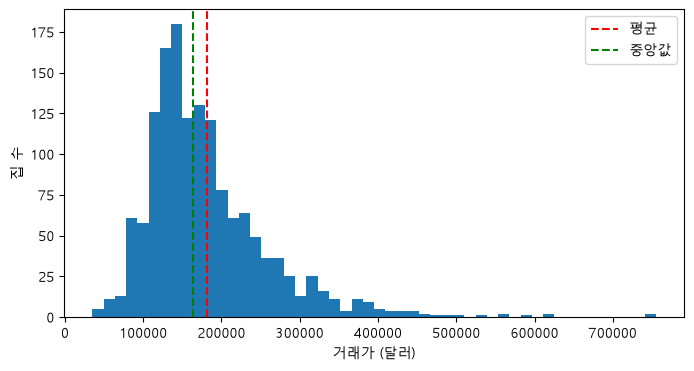

In [70]:
# [제공] 거래가 분포
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["SalePrice"], bins=50)
ax.axvline(df["SalePrice"].mean(), color="red", linestyle="--", label="평균")
ax.axvline(df["SalePrice"].median(), color="green", linestyle="--", label="중앙값")
ax.set_xlabel("거래가 (달러)")
ax.set_ylabel("집 수")
ax.legend()
plt.show()

> **[판단]** 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 이유는 무엇이고, 이 특징이 "모델이 크게 틀리는 집"에 어떤 영향을 줄 것 같나요?
>
> 나의 답: 해당 자료는 평균이 중앙값보다 큰 오른쪽 편향 분포를 보인다. 이에 따라 일부 극단적으로 비싼 집이 평균을 끌어올리고, 회귀 모델은 이런 극단값을 잘 맞히지 못해 예측과 실제 가격의 차이가 커질 가능성이 높다.

## 1-3. 빈 값 찾기

**[직접 작성]** 빈 값이 있는 열을 빈 값이 많은 순서로 10개 확인하세요.

<details><summary>힌트</summary>

`df.isna().sum()`은 열마다 빈 값의 수를 셉니다. `.sort_values(ascending=False)`로 정렬하고 `.head(10)`으로 위쪽만 보세요.
</details>

In [71]:
print(df.isna().sum().sort_values(ascending=False).head(10))

df['PoolQC'].value_counts()

PoolQC         1453
MiscFeature    1406
Alley          1369
Fence          1179
MasVnrType      872
FireplaceQu     690
LotFrontage     259
GarageYrBlt      81
GarageCond       81
GarageType       81
dtype: int64


PoolQC
Gd    3
Ex    2
Fa    2
Name: count, dtype: int64

> **[판단]** 수영장 품질(`PoolQC`)이 1,453채나 비어 있습니다. 정말로 정보가 없는 걸까요, 아니면 다른 뜻일까요? 데이터 설명서에서는 이런 열의 빈 값(NA)을 "해당 시설 없음"으로 정의합니다. 이 점을 알면 빈 값을 어떻게 다루겠습니까?
>
> 나의 답: 자료 기술표(data_description.txt)에 따르면 시설 등급은 Ex(Excellent) > Gd(Good) > TA(Typical) > Fa(Fair) > Po(Poor) 순이며, 시설이 없는 경우는 빈 값(NA)으로 기록되어 있다. 따라서 최하 등급 Po부터 최고 등급 Ex까지 1~5의 서열형 값을 부여하고, 시설이 없는 경우는 0으로 인코딩하려 한다.

## 1-4. 이 실습에서 쓰는 피처 정하기

79개를 전부 쓰면 첫 실습으로는 너무 많아서, 이 실습에서 쓸 피처 몇 개를 미리 골라 두었습니다. **[제공]** 셀을 실행해 목록을 확인하세요.

In [72]:
# [제공] 이 실습에서 쓰는 피처 목록
num_features = ["GrLivArea", "OverallQual", "YearBuilt", "YearRemodAdd", "TotalBsmtSF", "GarageCars",
                "GarageArea", "LotArea", "FullBath", "TotRmsAbvGrd", "Fireplaces", "1stFlrSF"]
cat_features = ["Neighborhood", "ExterQual", "KitchenQual", "BsmtQual", "CentralAir", "MSSubClass"]

print("숫자형:", num_features)
print("범주형:", cat_features)
print()
print("선택한 피처 중 빈 값이 있는 열:")
print(df[num_features + cat_features].isna().sum()[lambda s: s > 0])
print()
print("MSSubClass의 값:", sorted(df["MSSubClass"].unique().tolist()))

숫자형: ['GrLivArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'TotalBsmtSF', 'GarageCars', 'GarageArea', 'LotArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', '1stFlrSF']
범주형: ['Neighborhood', 'ExterQual', 'KitchenQual', 'BsmtQual', 'CentralAir', 'MSSubClass']

선택한 피처 중 빈 값이 있는 열:
BsmtQual    37
dtype: int64

MSSubClass의 값: [20, 30, 40, 45, 50, 60, 70, 75, 80, 85, 90, 120, 160, 180, 190]


> **[판단]** `MSSubClass`(주택 유형)는 20, 30, 60, 120… 처럼 숫자로 저장되어 있습니다. 이 숫자들은 "크기"를 뜻할까요? 이 열을 숫자 그대로 회귀에 넣으면 어떤 문제가 생길까요?
>
> 나의 답: 선형 모델은 MSSubClass 코드가 커질수록 가격이 일정하게 변한다고 가정해, 순서가 없는 주택 유형에 순서와 간격을 억지로 부여한다. 그 결과 코드 190(2가구 개조)이 크다는 이유로 가장 비싼 집처럼 예측되거나, 성격이 다른 유형 차이를 같은 단위로 취급하게 된다. 따라서 유형마다 별도의 열을 만드는 one-hot 인코딩으로 각 유형이 고유한 효과를 갖도록 해야 한다.

**[직접 작성]** 아래 두 가지를 처리하세요.

1. `MSSubClass`를 글자(범주)로 바꾼다
2. 범주형 피처(`cat_features`)의 빈 값을 `"None"`이라는 값으로 채운다

그다음 선택한 피처에 빈 값이 남지 않았는지 확인합니다.

<details><summary>힌트</summary>

`df["MSSubClass"] = df["MSSubClass"].astype(str)`, `df[cat_features] = df[cat_features].fillna("None")`. 확인은 `df[num_features + cat_features].isna().sum().sum()`이 0인지 보면 됩니다.
</details>

In [73]:
# 주택 유형 데이터형 변경
df['MSSubClass'] = df["MSSubClass"].astype(str)

# 지하실 높이 등급 결측값 채워 넣기
df[cat_features] = df[cat_features].fillna("None")

# 변경 확인
df[num_features + cat_features].isna().sum()

GrLivArea       0
OverallQual     0
YearBuilt       0
YearRemodAdd    0
TotalBsmtSF     0
GarageCars      0
GarageArea      0
LotArea         0
FullBath        0
TotRmsAbvGrd    0
Fireplaces      0
1stFlrSF        0
Neighborhood    0
ExterQual       0
KitchenQual     0
BsmtQual        0
CentralAir      0
MSSubClass      0
dtype: int64

> **[판단]** 범주형의 빈 값을 "None"이라는 값으로 채운 것은 1-3에서 본 "해당 시설 없음"이라는 설명서의 정의에 근거한 결정입니다. 이 결정이 틀릴 수 있는 경우를 하나 생각해 보세요. (예: 정말로 기록이 누락된 경우)
>
> 나의 답: 정말로 기록이 누락된 경우에 틀릴 수 있어서 지하실과 관련된 다른 변수들을 찾아보고 비교해볼 수 있다. 

## 1-5. 평가용 데이터 먼저 떼어 두기

Chapter 1과 같은 원칙입니다. 이후의 탐색과 시세 규칙은 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`로 합니다. (회귀 문제이므로 `stratify`는 쓰지 않습니다.)

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)`
</details>

In [74]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-4의 처리와 1-5의 분할을 한 번에 합니다. 끝낸 사람은 실행하지 않아도 됩니다.

In [75]:
# [제공] 체크포인트: 1-5까지 끝낸 사람은 실행하지 않아도 됩니다
# df = pd.read_csv("train.csv")
# df["MSSubClass"] = df["MSSubClass"].astype(str)
# df[cat_features] = df[cat_features].fillna("None")
# train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
# print(len(train_df), len(test_df))

### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `evaluate(이름, 예측)` | 평가용 데이터에서 MAE·RMSE·R²·MAPE를 보여 주고 지표를 돌려준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 (범주형은 원핫 인코딩) |
| `log_result(...)` | 실험 결과를 기록표에 한 줄 추가한다 |
| `run(이름, 피처, 모델)` | 모델을 학습하고 학습용·평가용 점수를 모두 채점해 기록한다 |
| `error_by_price(예측)` | 가격대별 집 수·MAE·평균 편향을 보여 준다 |

In [76]:
# [제공] 실습 도구
y_test = test_df["SalePrice"]
preds = {}          # 실험 이름 → 평가용 데이터의 예측값
experiment_log = []

def metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R²": r2_score(y, pred),
            "MAPE": mean_absolute_percentage_error(y, pred)}

def evaluate(name, pred, y_true=None):
    """예측을 채점합니다. y_true를 주지 않으면 평가용 데이터로 채점합니다."""
    store = y_true is None
    y_true = y_test if store else y_true
    pred = np.asarray(pred)
    m = metrics(y_true, pred)
    print(f"[{name}] MAE {m['MAE']:,.0f} | RMSE {m['RMSE']:,.0f} | R² {m['R²']:.3f} | MAPE {m['MAPE']*100:.1f}%")
    if store:
        preds[name] = pd.Series(pred, index=test_df.index)
    return m

def log_result(name, features, test, train=None):
    experiment_log.append({
        "실험": name,
        "피처 수": len(features) if features else "-",
        "학습 MAE": round(train["MAE"]) if train else None,
        "학습 RMSE": round(train["RMSE"]) if train else None,
        "평가 MAE": round(test["MAE"]),
        "평가 RMSE": round(test["RMSE"]),
        "평가 R²": round(test["R²"], 3),
    })

def make_data(features):
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["SalePrice"], test_df["SalePrice"]

def run(name, features, model):
    """모델을 학습하고 학습용·평가용 점수를 채점해 기록표에 남깁니다."""
    X_tr, X_te, y_tr, y_te = make_data(features)
    model.fit(X_tr, y_tr)
    m_tr = evaluate(name + " (학습용)", model.predict(X_tr), y_true=y_tr)
    m_te = evaluate(name, model.predict(X_te))
    log_result(name, features, m_te, m_tr)
    return model

_bins = [0, 100000, 200000, 300000, 500000, 800000]
def error_by_price(pred):
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    res = y_test - pred
    g = pd.cut(y_test, _bins)
    return pd.DataFrame({"집 수": g.value_counts().sort_index(),
                         "MAE": res.abs().groupby(g, observed=True).mean().round(0),
                         "평균 편향(실제−예측)": res.groupby(g, observed=True).mean().round(0)})

## 1-6. 집값과 관련 있어 보이는 정보 찾기

**[직접 작성]** 학습용 데이터(`train_df`)에서 두 가지를 확인하세요.

1. 숫자 열 중 거래가와 상관이 높은 열 10개
2. 동네(`Neighborhood`)별 거래가 중앙값 (높은 순)

<details><summary>힌트</summary>

상관은 `train_df.corr(numeric_only=True)["SalePrice"]`, 동네별 중앙값은 `train_df.groupby("Neighborhood")["SalePrice"].median()`입니다. 둘 다 `.sort_values(ascending=False)`로 정렬하세요.
</details>

In [77]:
display(train_df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False))

display(train_df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False))

SalePrice        1.000000
OverallQual      0.785555
GrLivArea        0.695652
GarageCars       0.640991
GarageArea       0.624139
TotalBsmtSF      0.597766
1stFlrSF         0.587883
FullBath         0.552546
TotRmsAbvGrd     0.520388
YearBuilt        0.516501
YearRemodAdd     0.508593
GarageYrBlt      0.480351
MasVnrArea       0.459123
Fireplaces       0.457549
BsmtFinSF1       0.359460
LotFrontage      0.330066
WoodDeckSF       0.329843
2ndFlrSF         0.314030
OpenPorchSF      0.299969
HalfBath         0.280481
LotArea          0.266204
BsmtFullBath     0.226346
BsmtUnfSF        0.222487
BedroomAbvGr     0.156211
ScreenPorch      0.119172
PoolArea         0.115630
3SsnPorch        0.051532
MoSold           0.041890
BsmtFinSF2      -0.005731
YrSold          -0.009099
LowQualFinSF    -0.011189
Id              -0.019643
MiscVal         -0.020179
BsmtHalfBath    -0.048346
OverallCond     -0.074391
KitchenAbvGr    -0.142785
EnclosedPorch   -0.149532
Name: SalePrice, dtype: float64

Neighborhood
NridgHt    314813.0
NoRidge    290000.0
StoneBr    282000.0
Veenker    245500.0
Somerst    226700.0
Timber     226250.0
ClearCr    211000.0
Crawfor    208550.0
CollgCr    200500.0
Gilbert    184000.0
NWAmes     183950.0
Blmngtn    181000.0
SawyerW    179200.0
Mitchel    156950.0
NPkVill    147000.0
NAmes      142000.0
SWISU      139500.0
Sawyer     134950.0
Blueste    124000.0
OldTown    124000.0
Edwards    123500.0
BrkSide    120000.0
IDOTRR     108950.0
BrDale     100000.0
MeadowV     89500.0
Name: SalePrice, dtype: float64

**[제공]** 거주 면적과 거래가의 관계를 그려 봅니다.

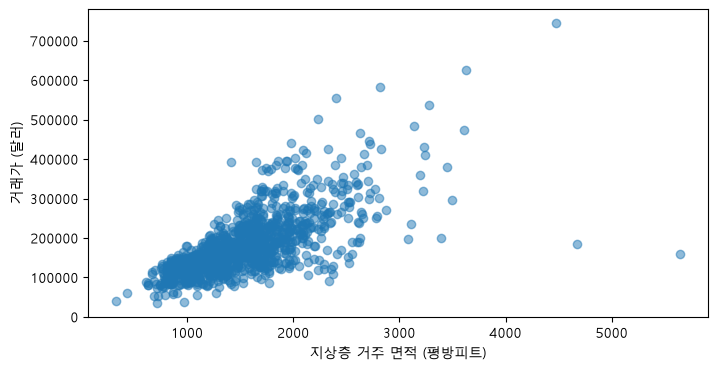

In [78]:
# [제공] 거주 면적과 거래가 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train_df["GrLivArea"], train_df["SalePrice"], alpha=0.5)
ax.set_xlabel("지상층 거주 면적 (평방피트)")
ax.set_ylabel("거래가 (달러)")
plt.show()

> **[판단]** 거래가와 가장 관련이 깊어 보이는 숫자 열 세 개를 적고, 왜 그럴지 한 줄씩 설명하세요.
>
> 나의 답: OverallQual(0.79), GrLivArea(0.70), GarageCars(0.64)는 모두 집의 규모와 품질을 나타내는 변수이므로 거래가와 상관이 높게 나타난다. OverallQual은 자재와 마감 등 종합 품질을 평가한 등급이므로 품질이 높은 집일수록 가격이 높다. GrLivArea와 GarageCars는 집의 크기를 나타내며, 면적과 차고 규모가 클수록 가격이 높아지는 경향이 있다.

> **[판단]** 산점도에서 눈에 띄는 점이 있나요? (예: 면적에 비해 값이 이상한 집) 이런 집을 모델에서 빼도 될까요, 두어야 할까요?
>
> 나의 답: 산점도에서 면적에 비해 가격이 유난히 높거나 낮은 집이 보이지만, 데이터 입력 오류가 의심되지 않는 한 제거하지 않는 것이 좋다. 이런 집은 동네나 주변 시설(Neighborhood, Condition1) 같은 다른 특성과 관련된 실제 차이를 담고 있을 수 있기 때문이다. 한편 면적이 클수록 가격의 흩어짐이 커지는 모습은 이분산성을 시사하므로, 이후 모델링에서 이를 고려할 필요가 있다.

---
# Part 2. 베이스라인 고르기

강의 2-1에서 회귀의 베이스라인은 "모든 집은 평균 가격"이라고 배웠습니다. 그런데 "평균 가격"만이 유일한 선택일까요?

## 2-1. 평균 예측과 중앙값 예측

**[직접 작성]** 학습용 데이터의 거래가 **평균**과 **중앙값**을 각각 평가용 집 전체의 예측값으로 쓴 두 베이스라인을 `evaluate`로 채점하고, 결과 지표를 `m_mean`, `m_median`에 저장하세요. 이어서 두 결과를 `log_result`로 기록합니다.

<details><summary>힌트</summary>

`mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())`로 같은 값을 반복한 배열을 만듭니다. 중앙값도 같은 방식입니다.

`m_mean = evaluate("평균 예측", mean_pred)`, 그다음 `log_result("평균 예측", [], m_mean)`.
</details>

In [79]:
# 1. 평균 예측
mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())
m_mean = evaluate("평균 예측", mean_pred)

# 2. 중앙값 예측
median_pred = np.full(len(test_df), train_df["SalePrice"].median())
m_median = evaluate("중앙값 예측", median_pred)

# 3. 예측 평가 출력
log_result("평균 예측", [], m_mean)
log_result("중앙값 예측", [], m_median)

[평균 예측] MAE 62,576 | RMSE 87,619 | R² -0.001 | MAPE 41.4%
[중앙값 예측] MAE 59,568 | RMSE 88,667 | R² -0.025 | MAPE 36.0%


> **[판단]** MAE와 RMSE에서 평균 예측과 중앙값 예측 중 어느 쪽이 더 낮은가요? 두 지표에서 결과가 다르다면, 왜 그럴지 "큰 오차를 얼마나 아프게 보는가"로 설명해 보세요.
>
> 나의 답: MAE에서는 중앙값 예측이, RMSE에서는 평균 예측이 더 낮게 나타났다. 이는 집값 분포가 오른쪽으로 치우쳐 평균이 중앙값보다 크므로 두 예측값 자체가 달라지고, 지표별 차이는 오차를 계산하는 방식에서 생겼다. MAE는 오차의 절댓값을 그대로 평균을 내므로 중앙값에서 가장 작아지고, RMSE는 오차를 제곱해 큰 오차에 더 큰 비중을 두므로 평균에서 가장 작아진다.

> **[판단]** 회귀 모델의 점수를 비교할 베이스라인으로는 둘 중 어느 것을 쓰겠습니까? 이유도 적으세요.
>
> 나의 답: 이 과제의 목표는 시세가 실제 거래가와 크게 어긋나는 경우를 줄이는 것이므로, 큰 오차에 더 큰 벌점을 주는 RMSE를 기준으로 삼는 것이 맞다. 따라서 RMSE가 더 낮은 평균 예측을 베이스라인으로 쓴다.

---
# Part 3. 현행 방법 만들기: 사람의 시세 규칙

모델이 없던 시절에도 중개사들은 나름의 규칙으로 시세를 매겼습니다. 비슷한 집의 평방피트당 단가에 면적을 곱하거나, 같은 동네의 비슷한 집이 얼마에 팔렸는지 떠올리는 식입니다. 여러분이 중개사라면 **정보 두세 개**로 어떤 규칙을 만들겠습니까?

**시세 규칙**: 어떤 정보를 어떻게 쓸지 **내가 정하고**, 숫자(동네별 단가 등)는 학습용 데이터에서 계산하는 방법입니다. Chapter 1에서 배운 규칙 기반(Rule-Based) 방법의 한 예로, 모델이 이겨야 할 비교 기준이 됩니다.

## 시세 규칙을 만들 때의 약속

- 쓰는 정보는 **두세 개를 넘기지 않습니다.** 머릿속으로 계산할 수 있어야 하기 때문입니다.
- 시세 규칙에 쓰는 숫자(동네별 단가, 구간별 중앙값 등)는 **학습용 데이터에서만** 계산합니다.
- 평가용 데이터를 보고 시세 규칙을 고치지 않습니다.

## 3-1. 나의 시세 규칙 만들기

> **[판단]** 나의 시세 규칙(말로): ________과 ________를 보고, ________를 기준으로 가격을 정한다.
>
> 이 정보를 고른 근거(1-6의 어떤 결과인가): 집 값과의 높은 상관관계 / 동네 별 집 값 차이
>
> 나의 답: 동네(Neighborhood)별 평방피트당 단가의 평균에 집의 거주 면적(GrLivArea)을 곱해 가격을 정한다.

**[직접 작성]** 시세 규칙을 코드로 옮겨 평가용 집의 가격을 계산하고, 예측을 `rule_pred`(평가용 `test_df`와 같은 순서의 `Series`)에 저장하세요. 그다음 `evaluate`로 채점하고, 결과를 `m_rule`에 저장한 뒤 `log_result`로 기록합니다.

<details><summary>힌트</summary>

학습용 데이터에서 평방피트당 단가를 구하는 예시입니다.

```python
unit_price = (train_df["SalePrice"] / train_df["GrLivArea"]).median()
rule_pred = test_df["GrLivArea"] * unit_price
```

동네별로 단가를 다르게 쓰려면 단가를 동네별로 구한 뒤 `map`으로 붙입니다.

```python
unit_by_nb = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["Neighborhood"]).median()
rule_pred = test_df["Neighborhood"].map(unit_by_nb) * test_df["GrLivArea"]
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 시세 규칙을 쓰세요. 평가용에만 있는 동네가 있을 수 있으니, 빈 값이 생기면 `fillna(train_df["SalePrice"].median())`처럼 채우세요.
</details>

In [97]:
# 동네별 평방피트당 단가의 평균 (학습용 데이터로만 계산)
unit_by_nb = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["Neighborhood"]).mean()

# 평가용 집에 동네 단가를 붙이고 면적을 곱함, 없는 동네는 전체 단가 평균으로 채움
rule_pred = test_df["Neighborhood"].map(unit_by_nb).fillna(unit_by_nb.mean()) * test_df["GrLivArea"]

m_rule = evaluate("내 시세 규칙", rule_pred)
log_result("내 시세 규칙", ["Neighborhood", "GrLivArea"], m_rule)



[내 시세 규칙] MAE 31,439 | RMSE 43,825 | R² 0.750 | MAPE 19.1%


> **[판단]** 내 시세 규칙의 MAE는 베이스라인(평균·중앙값 예측)보다 얼마나 낮은가요? 정보 두세 개만으로 오차가 이만큼 줄어든다는 것은 무엇을 뜻할까요?
>
> 나의 답: 내 시세 규칙의 MAE(31,439달러)는 평균 예측(62,576달러)보다 약 31,100달러(49.8%), 중앙값 예측(59,568달러)보다 약 28,100달러(47.2%) 낮다. 동네와 면적이라는 두 정보만으로 평균 오차가 절반 가까이 줄어든다는 것은, 집값의 큰 부분이 위치와 규모로 설명된다는 뜻이다. 다만 MAPE 19.1%는 여전히 상당한 오차이므로, 기획팀이 말하는 "믿을 만한 시세"인지는 가격대별 오차로 따져 봐야 한다.

---
# Part 4. 모델 만들기와 실험 기록

이제 모델을 만들어 내 시세 규칙과 겨룹니다. 강의 Part 2의 코드를 보지 말고 먼저 직접 써 보세요.

## 4-1. 첫 모델: 다중회귀

**[직접 작성]** 아래 순서로 작성하세요.

1. 피처 `["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]`로 `make_data`를 호출해 `X_train, X_test, y_train, y_test`를 만든다
2. `LinearRegression`을 학습한다
3. 학습용과 평가용을 모두 `evaluate`로 채점한다 (학습용은 `y_true=y_train`을 줍니다)
4. 평가용 결과를 `log_result`로 기록한다

<details><summary>힌트</summary>

강의 2-3의 코드와 같은 순서입니다.

```python
m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))
log_result("다중회귀 5개", features, m_test, m_train)
```
</details>

In [81]:
features = ["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]
X_train, X_test, y_train, y_test = make_data(features)

model = LinearRegression().fit(X_train, y_train)

m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))
log_result("다중회귀 5개", features, m_test, m_train)

[학습용] MAE 24,399 | RMSE 37,970 | R² 0.758 | MAPE 14.5%
[다중회귀 5개] MAE 25,415 | RMSE 39,763 | R² 0.794 | MAPE 15.3%


> **[판단]** 이 모델의 학습용 점수와 평가용 점수는 얼마나 차이 나나요? 그 차이는 과적합의 신호일까요?
>
> 나의 답: 학습용 MAE(24,399달러)와 평가용 MAE(25,415달러)의 차이는 약 1,000달러로 작고, R²는 오히려 평가용(0.794)이 학습용(0.758)보다 높다. 따라서 학습 데이터에만 맞춰진 과적합의 신호는 뚜렷하지 않으며, 이 모델은 새로운 집에도 비슷한 수준으로 예측한다고 볼 수 있다.

## 4-2. 피처와 모델을 바꿔 보기

피처를 늘리거나 모델의 복잡도를 바꿔 가며 **세 번 이상** 실험하세요. 매번 아래 `run`이 학습용·평가용 점수를 모두 채점해 기록해 줍니다.

**[직접 작성]** `run(이름, 피처 목록, 모델)`을 세 번 이상 호출하세요. 다음 세 가지를 모두 포함하면 좋습니다.

- 숫자 피처만 늘려 보기
- 범주형 피처(동네, 마감 품질 등)를 더해 보기
- 모델의 복잡도를 올려 보기 (다항 피처)와, 그에 벌점을 주는 Ridge

<details><summary>힌트</summary>

```python
run("숫자 12개", num_features, LinearRegression())
run("숫자+범주", num_features + cat_features, LinearRegression())
run("3차 다항", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))
run("3차 다항 + Ridge", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=100)))
```

`alpha`(벌점의 세기)를 10, 100, 1000으로 바꿔 보면 학습용·평가용 점수가 어떻게 달라지는지 볼 수 있습니다.
</details>

In [82]:
# 시험 1: 숫자 12개 + Ridge
for alpha in [10, 100, 1000]:
    run(f"시험 1 · 숫자 12개 Ridge {alpha}", num_features,
        make_pipeline(StandardScaler(), Ridge(alpha=alpha)))

# 시험 2: 숫자 + 범주형 + Ridge
for alpha in [10, 100, 1000]:
    run(f"시험 2 · 숫자+범주 Ridge {alpha}", num_features + cat_features,
        make_pipeline(StandardScaler(), Ridge(alpha=alpha)))

# 시험 3: 3차 다항 + Ridge
for alpha in [10, 100, 1000]:
    run(f"시험 3 · 3차 다항 Ridge {alpha}", num_features,
        make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=alpha)))


[시험 1 · 숫자 12개 Ridge 10 (학습용)] MAE 22,953 | RMSE 36,607 | R² 0.775 | MAPE 13.6%
[시험 1 · 숫자 12개 Ridge 10] MAE 24,316 | RMSE 39,276 | R² 0.799 | MAPE 14.5%
[시험 1 · 숫자 12개 Ridge 100 (학습용)] MAE 22,881 | RMSE 36,747 | R² 0.774 | MAPE 13.4%
[시험 1 · 숫자 12개 Ridge 100] MAE 24,119 | RMSE 39,708 | R² 0.794 | MAPE 14.2%
[시험 1 · 숫자 12개 Ridge 1000 (학습용)] MAE 23,750 | RMSE 39,128 | R² 0.743 | MAPE 13.3%
[시험 1 · 숫자 12개 Ridge 1000] MAE 24,581 | RMSE 43,584 | R² 0.752 | MAPE 13.8%
[시험 2 · 숫자+범주 Ridge 10 (학습용)] MAE 18,375 | RMSE 29,730 | R² 0.852 | MAPE 10.6%
[시험 2 · 숫자+범주 Ridge 10] MAE 20,107 | RMSE 32,729 | R² 0.860 | MAPE 11.9%
[시험 2 · 숫자+범주 Ridge 100 (학습용)] MAE 18,286 | RMSE 30,030 | R² 0.849 | MAPE 10.4%
[시험 2 · 숫자+범주 Ridge 100] MAE 19,875 | RMSE 33,131 | R² 0.857 | MAPE 11.7%
[시험 2 · 숫자+범주 Ridge 1000 (학습용)] MAE 18,946 | RMSE 32,237 | R² 0.826 | MAPE 10.7%
[시험 2 · 숫자+범주 Ridge 1000] MAE 20,822 | RMSE 36,451 | R² 0.827 | MAPE 12.2%
[시험 3 · 3차 다항 Ridge 10 (학습용)] MAE 12,571 | RMSE 18,059 | R² 0.945 | MA

**[제공]** 실험 기록표를 평가 MAE 순으로 봅니다.

In [83]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("평가 MAE")

,실험,피처 수,학습 MAE,학습 RMSE,평가 MAE,평가 RMSE,평가 R²
8,시험 2 · 숫자+범주 Ridge 100,18,18286.0,30030.0,19875,33131,0.857
7,시험 2 · 숫자+범주 Ridge 10,18,18375.0,29730.0,20107,32729,0.860
11,시험 3 · 3차 다항 Ridge 100,12,13872.0,19911.0,20222,32073,0.866
9,시험 2 · 숫자+범주 Ridge 1000,18,18946.0,32237.0,20822,36451,0.827
12,시험 3 · 3차 다항 Ridge 1000,12,17013.0,23963.0,20858,31688,0.869
10,시험 3 · 3차 다항 Ridge 10,12,12571.0,18059.0,22671,41122,0.780
5,시험 1 · 숫자 12개 Ridge 100,12,22881.0,36747.0,24119,39708,0.794
4,시험 1 · 숫자 12개 Ridge 10,12,22953.0,36607.0,24316,39276,0.799
6,시험 1 · 숫자 12개 Ridge 1000,12,23750.0,39128.0,24581,43584,0.752
3,다중회귀 5개,5,24399.0,37970.0,25415,39763,0.794


> **[판단]** 범주형 피처(동네, 마감 품질 등)를 더했을 때 오차가 얼마나 줄었나요? 이 피처들이 왜 도움이 되었을까요?
>
> 나의 답: 전범주형 변수를 넣었을 때 오차가 줄어든 이유는 이 변수들이 실제로 구매자가 집을 고를 때 보는 조건을 담고 있기 때문이다. 특히 Neighborhood(동네)는 같은 면적이라도 어디에 있느냐에 따라 가격이 크게 달라지므로 가장 큰 영향을 줄 것으로 예상된다. 또한 외장과 주방, 지하실의 품질 등급(ExterQual, KitchenQual, BsmtQual)과 주택 유형(MSSubClass)은 숫자 피처만으로는 드러나지 않는 마감 수준과 구조 차이를 보여 준다. 실제로 숫자 12개 Ridge(평가 MAE 약 24,100달러)에서 범주형을 더한 뒤 약 19,900달러로 내려간 것도 이 정보가 가격을 잘 설명한다는 점을 시사한다.

> **[판단]** 학습용 점수와 평가용 점수의 차이가 가장 큰 실험은 무엇인가요? Ridge를 쓰면 그 차이가 어떻게 달라졌나요? 강의 Part 3의 "과적합"과 "정규화"로 설명해 보세요.
>
> 나의 답: 학습용과 평가용의 차이가 가장 큰 실험은 **시험 3 · 3차 다항 Ridge(alpha=10)**이다. 학습용 MAE 12,571달러에 비해 평가용 MAE는 22,671달러로 약 1만 달러 차이가 나며, 이는 학습 데이터의 특성까지 외운 과적합의 신호이다. Ridge는 계수가 지나치게 커지지 않도록 벌점을 주는 정규화로, alpha가 커질수록 계수가 0 쪽으로 강하게 줄어 모델의 복잡도가 억제된다. 그 결과 alpha=1000에서는 학습용과 평가용의 차이가 약 3,800달러로 줄어든다.

> **[판단]** 가장 좋은 모델은 내 시세 규칙보다 MAE가 얼마나(달러, %) 낮은가요? 이 차이라면 기획팀이 모델을 도입할 만할까요?
>
> 나의 답: 가장 좋은 모델(시험 2 · 숫자+범주 Ridge 100)의 평가 MAE는 19,875달러로, 내 시세 규칙(31,439달러)보다 약 11,600달러(36.8%) 낮다. 학습용과 평가용 MAE의 차이도 약 1,600달러로 작고 평가 R²도 0.857로 높아서, 기획팀이 도입을 검토할 만한 수준이다. 다만 평가 MAPE가 약 11.7%이므로, 도입 전에 가격대별 오차를 확인해 어떤 집에서 특히 오차가 큰지 보고해야 한다.

## 4-3. Lasso: 피처를 고르는 정규화

4-2의 Ridge는 계수를 **고르게 줄이는** 정규화였습니다. **Lasso**는 벌점의 모양이 달라서, 덜 중요한 계수를 **정확히 0**으로 만듭니다. 계수가 0인 피처는 모델에서 빠진 것과 같으므로, Lasso는 정규화이면서 동시에 피처를 고르는 방법입니다.

| | Ridge | Lasso |
| --- | --- | --- |
| 벌점 | 계수의 제곱합 | 계수의 절댓값합 |
| 계수가 줄어드는 방식 | 모두 고르게, 0이 되지는 않음 | 덜 중요한 것부터 정확히 0 |

이 절에서는 Lasso가 실제로 어떤 피처를 버리는지 세 가지 실험으로 확인합니다. 세 실험 모두 실험 기록표(`experiment_log`)에는 남기지 않습니다.

### 실험 1. 계수 비교: 무엇이 0이 되는가

**[직접 작성]** 숫자 피처 12개(`num_features`)로 세 모델을 학습하고, 계수를 한 표로 비교하세요. 세 모델 모두 `StandardScaler`를 앞에 붙입니다(표준화해야 계수끼리 비교할 수 있습니다).

- 선형회귀 (`LinearRegression()`)
- Ridge (`Ridge(alpha=100)`)
- Lasso (`Lasso(alpha=5000)`)

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features)
coefs = {}
for name, reg in [("선형회귀", LinearRegression()), ("Ridge 100", Ridge(alpha=100)), ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_          # 파이프라인의 마지막 단계(모델)의 계수
pd.DataFrame(coefs, index=X_tr.columns).round(0)
```

`m[-1]`은 파이프라인의 마지막 단계, 즉 모델입니다.
</details>

In [84]:
X_tr, X_te, y_tr, y_te = make_data(num_features)

coefs = {}
for name, reg in [("선형회귀", LinearRegression()), ("Ridge 100", Ridge(alpha=100)), ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_

pd.DataFrame(coefs, index=X_tr.columns).round(0)

,선형회귀,Ridge 100,Lasso 5000
GrLivArea,21092.0,16753.0,19576.0
OverallQual,26459.0,23642.0,27385.0
YearBuilt,8745.0,8074.0,5089.0
YearRemodAdd,7366.0,7685.0,4259.0
TotalBsmtSF,6347.0,6859.0,5948.0
GarageCars,7082.0,6667.0,6992.0
GarageArea,3930.0,5248.0,3068.0
LotArea,6052.0,5598.0,2517.0
FullBath,-3116.0,-790.0,0.0
TotRmsAbvGrd,1805.0,4033.0,0.0


> **[판단]** Lasso가 0으로 만든 피처는 무엇인가요? 그 피처들은 집값과 정말 관계가 없을까요? 1-6의 상관표나 다른 피처와의 관계를 떠올려 설명해 보세요.
>
> 나의 답: Lasso가 0으로 만든 피처는 FullBath(욕실 수)와 TotRmsAbvGrd(지상층 방 수)이다. 이 두 피처가 집값과 전혀 관계가 없는 것은 아니다. 두 피처는 집의 크기를 나타내는 GrLivArea(지상층 생활 면적)와 강하게 얽혀 있어서, 면적이 이미 설명하는 정보를 중복으로 담고 있기 때문이다. Lasso는 이런 중복된 피처 중 하나를 남기고 나머지는 0으로 없애므로, 쓸모없어서가 아니라 다른 피처와 정보가 겹쳐서 제외된 것이다. 실제로 선형회귀에서 FullBath의 계수가 음수로 나온 것도 이 중복 때문이다.

### 실험 2. 잡음 피처를 섞으면

**[제공]** 아무 의미 없는 무작위 숫자 열 5개(`noise0`~`noise4`)를 데이터에 추가합니다. 집값과 전혀 관계가 없는 열입니다.

In [85]:
# [제공] 무작위 잡음 피처 5개 추가 (씨앗 고정)
rng = np.random.RandomState(0)
noise_features = [f"noise{i}" for i in range(5)]
for col in noise_features:
    df[col] = rng.randn(len(df))
print(df[noise_features].describe().round(2).loc[["mean", "std"]])

      noise0  noise1  noise2  noise3  noise4
mean   -0.02   -0.03   -0.02    0.02   -0.02
std     0.98    0.96    1.01    0.99    0.99


**[직접 작성]** `num_features + noise_features`로 선형회귀와 Lasso(`alpha=1000`)를 학습하세요. 각 모델에서

1. 잡음 피처 5개의 계수
2. 계수가 정확히 0이 된 피처 목록
3. 평가용 점수 (`evaluate`로 채점)

를 출력합니다.

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)
m = make_pipeline(StandardScaler(), Lasso(alpha=1000)).fit(X_tr, y_tr)
coef = pd.Series(m[-1].coef_, index=X_tr.columns)
print(coef[noise_features].round(0))
print("0이 된 피처:", list(coef[coef == 0].index))
evaluate("Lasso + 잡음", m.predict(X_te))
```
</details>

In [86]:
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)

# 1. 선형회귀: 잡음 피처 5개의 계수
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
lin_coef = pd.Series(lin[-1].coef_, index=X_tr.columns)
print("선형회귀 잡음 계수:")
print(lin_coef[noise_features].round(0))

# 2. Lasso: 계수가 정확히 0이 된 피처
m = make_pipeline(StandardScaler(), Lasso(alpha=1000)).fit(X_tr, y_tr)
coef = pd.Series(m[-1].coef_, index=X_tr.columns)
print("Lasso에서 0이 된 피처:", list(coef[coef == 0].index))

# 3. 평가용 점수
evaluate("선형회귀 + 잡음", lin.predict(X_te))
evaluate("Lasso + 잡음", m.predict(X_te))


선형회귀 잡음 계수:
noise0   -696.0
noise1    497.0
noise2   -144.0
noise3   -732.0
noise4   -175.0
dtype: float64
Lasso에서 0이 된 피처: ['FullBath', 'noise0', 'noise1', 'noise2', 'noise3', 'noise4']
[선형회귀 + 잡음] MAE 24,300 | RMSE 39,230 | R² 0.799 | MAPE 14.5%
[Lasso + 잡음] MAE 24,184 | RMSE 39,522 | R² 0.796 | MAPE 14.3%


{'MAE': 24183.798977587878,
 'RMSE': np.float64(39521.50787399574),
 'R²': 0.7963646470249526,
 'MAPE': 0.14282195875417453}

> **[판단]** 선형회귀는 잡음 피처에 어떤 계수를 주었나요? 이 계수표만 보고 보고서를 쓰면 어떤 오해가 생길까요? Lasso는 잡음을 어떻게 다뤘고, 평가용 점수는 어떻게 달라졌나요?
>
> 나의 답: 선형회귀는 잡음 피처 5개에 각각 −696, 497, −144, −732, −175달러 수준의 0이 아닌 계수를 주었다. 계수 크기가 수백 달러 단위라 예측 오차(MAE 2만 달러 안팎)에 비하면 작지만 0은 아니다. 이 계수표만 보고 보고서를 쓰면 무작위로 만든 열이 집값에 실제로 영향을 준다는 잘못된 결론이 나올 수 있다. 잡음은 실제 관계가 없는 값이므로, 이 계수들은 데이터의 우연에서 생긴 값이고 부호도 제각각이다. 반면 Lasso는 잡음 피처 5개의 계수를 모두 정확히 0으로 만들어 모델에서 제외했다. 평가용 점수는 MAE 24,184달러, R² 0.796으로, 잡음 없는 시험 1 Ridge(MAE 24,316달러)와 비슷하거나 약간 좋아서 잡음이 성능을 해치지 않았다.

### 실험 3. 범주형까지 넣은 모델에 Lasso를 걸면

**[직접 작성]** 4-2에서 가장 좋았던 피처 조합(`num_features + cat_features`, 원핫 인코딩 후 열 67개)에 Lasso를 걸고, `alpha`를 100, 300, 1000, 3000으로 바꿔 가며 다음을 표로 정리하세요.

- 0이 아닌 계수의 수
- 평가용 MAE와 RMSE

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a, "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})
pd.DataFrame(rows)
```

비교 기준은 실험 기록표의 "숫자+범주"(선형회귀) 줄입니다.
</details>

In [87]:
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a, "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})
pd.DataFrame(rows)


,alpha,남은 피처 수,평가 MAE,평가 RMSE
0,100,58,20090,32704
1,300,49,20030,32767
2,1000,35,19946,33056
3,3000,25,20717,34903


> **[판단]** Lasso는 "숫자+범주" 선형회귀보다 나아졌나요? MAE와 RMSE가 같은 방향으로 움직였나요? 4-2의 3차 다항 실험에서 Ridge가 큰 효과를 냈던 것과 비교해, 여기서 효과가 작은 이유를 "이 모델이 과적합했는가"로 설명해 보세요.
>
> 나의 답: MAE는 Ridge보다 약 50~200달러 높고, RMSE는 alpha 100과 300에서 조금 낮다. 이 정도 차이는 우연한 변동 범위로 볼 수 있다. 대신 alpha 1000은 피처를 35개로 줄이면서도 오차는 비슷하게 유지했으므로, 정확도를 거의 포기하지 않고 모델을 단순하게 만든 결과로 보는 것이 맞다. alpha 3000은 피처를 너무 많이 줄여 오차가 커졌다(과소적합).

> **[판단]** 기획팀이 "피처를 절반만 써도 비슷하다면 더 단순한 모델이 낫지 않나요?"라고 묻습니다. 어떻게 답하겠습니까?
>
> 나의 답: 정확도 차이가 거의 없다면 피처가 적은 모델을 쓰는 것이 낫다. 다만 절반을 줄였다는 사실만으로 단순하다고 판단하기보다, 어떤 피처가 빠졌는지를 함께 확인해야 한다. 예를 들어 동네처럼 현업에서 설명하기 쉬운 정보가 빠졌다면, 단순한 모델이라도 설명력이 떨어질 수 있다.

---
# Part 5. 오차 들여다보기와 보고

지표 하나로는 "믿어도 되는 집"과 "믿으면 안 되는 집"을 구분할 수 없습니다. 오차가 어디에 몰려 있는지 직접 봅니다.

## 5-1. 가격대별 오차

**[직접 작성]** 기록표에서 평가 MAE가 가장 낮은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 실험의 예측을 `best_pred`에 저장하세요. 그다음 `error_by_price`로 **내 시세 규칙**과 **최고 모델**의 가격대별 오차를 각각 출력합니다.

<details><summary>힌트</summary>

모든 실험의 예측은 `preds`에 이름으로 저장되어 있습니다. `best_name = "숫자+범주"`처럼 이름을 직접 적고 `best_pred = preds[best_name]`로 꺼내세요.

`error_by_price(preds["내 시세 규칙"])`, `error_by_price(best_pred)`
</details>

In [99]:
best_name = "시험 2 · 숫자+범주 Ridge 100"   # 기록표에서 평가 MAE가 가장 낮은 실험
best_pred = preds[best_name]

print("[내 시세 규칙]")
display(error_by_price(preds["내 시세 규칙"]))

print("[최고 모델]")
display(error_by_price(best_pred))

[내 시세 규칙]


,집 수,MAE,평균 편향(실제−예측)
SalePrice,,,
"(0, 100000]",26,24395.0,-11987.0
"(100000, 200000]",184,24928.0,-5807.0
"(200000, 300000]",58,39666.0,-8700.0
"(300000, 500000]",21,55373.0,32640.0
"(500000, 800000]",3,165229.0,165229.0


[최고 모델]


,집 수,MAE,평균 편향(실제−예측)
SalePrice,,,
"(0, 100000]",26,21049.0,-15418.0
"(100000, 200000]",184,13378.0,-2665.0
"(200000, 300000]",58,23830.0,4438.0
"(300000, 500000]",21,38105.0,27732.0
"(500000, 800000]",3,204078.0,204078.0


> **[판단]** 어느 가격대에서 오차(MAE)가 가장 큰가요? 그 가격대의 "평균 편향"은 양수(실제가 더 비쌈)인가요, 음수인가요? 모델과 시세 규칙이 같은 방향으로 틀리나요?
>
> 나의 답: 나의 답: 두 방법 모두 50만~80만 달러 구간에서 오차가 가장 컸다. 이 구간의 MAE는 시세 규칙이 165,229달러, 최고 모델이 204,078달러였고, 평균 편향은 두 방법 모두 양수(시세 규칙 +165,229, 모델 +204,078)였다. 즉 비싼 집을 실제보다 낮게 예측하는 과소 예측이 두 방법에서 같은 방향으로 나타났다. 다만 이 구간에는 3채뿐이라 표본이 너무 적어 결론을 내리기는 어렵다. 반대로 10만 달러 이하 구간에서는 두 방법 모두 편향이 음수(과대 예측)였다.

## 5-2. 잔차 그림

**[직접 작성]** 최고 모델의 잔차(실제 − 예측)를 예측 가격에 대해 산점도로 그리세요. 0을 나타내는 가로선도 함께 그립니다.

<details><summary>힌트</summary>

강의 2-7의 코드와 같습니다.

```python
residual = y_test - best_pred
plt.scatter(best_pred, residual, alpha=0.5)
plt.axhline(0, color="gray")
```
</details>

c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


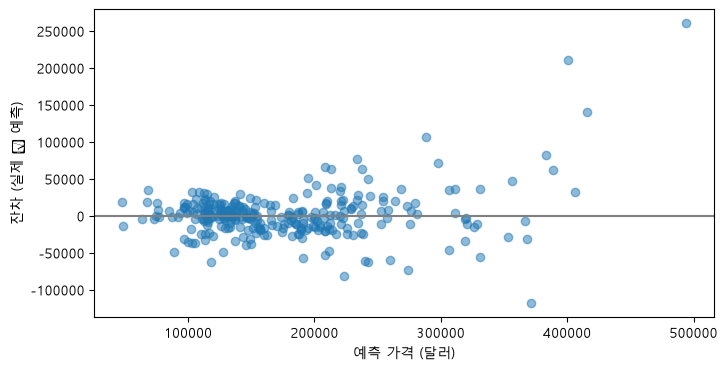

In [89]:
residual = y_test - best_pred
plt.figure(figsize=(8, 4))
plt.scatter(best_pred, residual, alpha=0.5)
plt.axhline(0, color="gray")
plt.xlabel("예측 가격 (달러)")
plt.ylabel("잔차 (실제 − 예측)")
plt.show()


> **[판단]** 잔차 그림에서 규칙이 보이나요? 예측 가격이 높은 쪽에서 점들이 어떻게 흩어져 있나요?
>
> 나의 답: 잔차 그림에서는 이분산성이 뚜렷하게 나타난다. 예측 가격이 낮은 구간(10만~20만 달러)에서는 잔차가 대략 ±5만 달러 안에 모여 있지만, 가격이 높아질수록 점들의 흩어짐이 커져서 부채꼴 모양이 된다. 예측 가격이 35만 달러 이상인 구간에서는 잔차가 대체로 0보다 위에 있어, 비싼 집을 실제보다 낮게 예측하는 과소 예측 경향이 보인다. 다만 음의 잔차도 일부 있으므로 과소 예측이 모든 고가 매물에서 일관되게 나타나는 것은 아니며, 고가 구간의 표본이 적어 추가 확인이 필요하다.

## 5-3. 가장 크게 틀린 집 들여다보기

**[직접 작성]** 최고 모델이 가장 크게 틀린 집 10채를 골라 실제 거래가, 예측 가격, 면적(`GrLivArea`), 품질(`OverallQual`), 동네(`Neighborhood`)를 한 표로 출력하세요.

<details><summary>힌트</summary>

`test_df.assign(예측=best_pred, 오차=y_test - best_pred)`로 열을 붙인 뒤, 오차의 절댓값으로 정렬합니다. `sort_values("오차", key=abs, ascending=False).head(10)`.
</details>

In [90]:
worst = (test_df.assign(예측=best_pred, 오차=y_test - best_pred)
                .sort_values("오차", key=abs, ascending=False)
                .head(10))
worst[["SalePrice", "예측", "오차", "GrLivArea", "OverallQual", "Neighborhood"]]


,SalePrice,예측,오차,GrLivArea,OverallQual,Neighborhood
691,755000,494122.568643,260877.431357,4316,10,NoRidge
898,611657,401043.911843,210613.088157,2364,9,NridgHt
1046,556581,415836.068946,140744.931054,2868,9,StoneBr
581,253293,371074.947590,-117781.947590,2042,8,NridgHt
774,395000,288604.342711,106395.657289,1973,8,NridgHt
1243,465000,382981.127732,82018.872268,2076,10,NridgHt
588,143000,223700.164084,-80700.164084,1473,5,ClearCr
218,311500,234029.115909,77470.884091,1954,7,Crawfor
529,200624,274354.303251,-73730.303251,2515,6,Crawfor
585,369900,297763.540645,72136.459355,2028,8,Timber


> **[판단]** 크게 틀린 집들에게 공통점이 있나요? 기획팀이 "이런 매물에는 자동 시세를 쓰지 말자"고 한다면 어떤 기준(가격대, 품질 등)을 제안하겠습니까?
>
> 나의 답: 10채 중 7채는 실제 거래가가 30만 달러 이상인 고가 매물이었고, 7채는 종합 품질(OverallQual)이 8 이상이었다. 동네도 NridgHt(4채), NoRidge, StoneBr, Timber처럼 고가 동네에 몰려 있었다. 방향은 대부분 과소 예측이었다. 실제가 예측보다 높은 집이 7채였고, 과대 예측된 집은 3채(581, 588, 529번)였다. 따라서 기획팀에는 "예측 가격이 30만 달러 이상이거나 종합 품질이 8 이상인 매물은 자동 시세를 제시하지 말고 담당자가 직접 감정하도록 하자"고 제안하겠다. 이 기준은 오차가 큰 집을 대부분 걸러내면서도, 중저가 매물에는 자동 시세를 계속 쓸 수 있다.

## 5-4. 가격 맞히기

곧 다른 수강생들의 결과와 함께 비교합니다. 그 전에 **사람의 감**으로 세 채의 가격을 먼저 맞혀 봅니다.

**[제공]** 평가용 집 세 채의 정보를 보여 줍니다. (거래가는 보여 주지 않습니다.)

In [91]:
# [제공] 맞혀 볼 집 세 채 (거래가는 숨김)
_s = test_df.sort_values("SalePrice")
guess_ids = [_s.index[int(q * (len(_s) - 1))] for q in (0.05, 0.5, 0.99)]
show_cols = ["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars", "KitchenQual"]
test_df.loc[guess_ids, show_cols]

,Neighborhood,GrLivArea,OverallQual,YearBuilt,TotalBsmtSF,GarageCars,KitchenQual
649,MeadowV,630,4,1970,630,0,TA
1299,NAmes,1246,5,1959,1246,1,Gd
1243,NridgHt,2076,10,2006,2076,3,Ex


**[직접 작성]** 위 표만 보고, 세 집의 거래가를 직관으로 적으세요. (`my_guess`의 0을 달러 숫자로 바꿉니다.)

In [102]:
# 위 표의 순서대로 세 집의 거래가(달러)를 적으세요
my_guess = {guess_ids[0]: 100000, guess_ids[1]: 250000, guess_ids[2]: 400000}

**[제공]** 실제 거래가를 공개합니다. 내 감, 내 시세 규칙, 최고 모델의 예측을 나란히 봅니다.

In [103]:
# [제공] 정답 공개
reveal = pd.DataFrame({
    "실제 거래가": y_test.loc[guess_ids],
    "내 감": pd.Series(my_guess),
    "내 시세 규칙": preds["내 시세 규칙"].loc[guess_ids],
    "최고 모델": best_pred.loc[guess_ids],
})
for col in ["내 감", "내 시세 규칙", "최고 모델"]:
    reveal[col + " 오차"] = (reveal[col] - reveal["실제 거래가"]).abs()
reveal.round(0)

,실제 거래가,내 감,내 시세 규칙,최고 모델,내 감 오차,내 시세 규칙 오차,최고 모델 오차
649,84500,100000,61544.0,76618.0,15500,22956.0,7882.0
1299,154000,250000,144568.0,140636.0,96000,9432.0,13364.0
1243,465000,400000,334556.0,382981.0,65000,130444.0,82019.0


> **[판단]** 세 방법(내 감, 내 시세 규칙, 모델) 중 가장 가까웠던 것은 무엇인가요? 가장 비싼 집에서는 어땠나요? 5-1의 결과와 연결해서 설명해 보세요.
>
> 나의 답: 세 집 중 가까운 방법은 집마다 달랐다. 최고 모델은 84,500달러 집(오차 7,882달러), 시세 규칙은 154,000달러 집(오차 9,432달러), 내 감은 465,000달러 집(오차 65,000달러)에서 가장 가까웠다. 가장 비싼 집에서는 세 방법 모두 과소 예측했고, 시세 규칙의 오차(130,444달러)가 가장 컸다. 세 채뿐이라 감이 고가 집에서 항상 낫다고 보기는 어렵다.

## 5-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

시세 규칙은 나의 시세 규칙 하나만 있는 것이 아닙니다. 다른 정보를 골랐다면 결과도 달랐을 것입니다. 다음 절에서는 아래 **후보 정보 5개** 중 1개 또는 2개를 고르고, **계산법 2가지** 중 하나를 쓰는 시세 규칙을 **모두** 만들어 채점합니다. 정보 조합 5 + 10 = 15가지 × 계산법 2가지 = **30개**입니다.

| 후보 정보 | 나누는 방법 |
| --- | --- |
| 동네 (`Neighborhood`) | 동네 이름 그대로 |
| 품질 등급 (`OverallQual`) | 1~10 등급 그대로 |
| 거주 면적 (`GrLivArea`) | 학습용 기준 5구간 (집 수가 같도록) |
| 건축 연도 (`YearBuilt`) | 학습용 기준 5구간 (집 수가 같도록) |
| 차고 차량 수 (`GarageCars`) | 0~4대 그대로 |

| 계산법 | 뜻 |
| --- | --- |
| (가) 그룹 중앙값 | 같은 그룹 집들의 거래가 중앙값을 그대로 시세로 쓴다 |
| (나) 그룹 단가 × 면적 | 같은 그룹 집들의 평방피트당 단가 중앙값에 그 집의 거주 면적을 곱한다 |

예: "동네 + 품질 등급, (가)"는 "같은 동네·같은 품질 등급 집들의 거래가 중앙값"을 시세로 쓰는 규칙입니다. 모든 그룹의 숫자는 학습용 데이터에서만 계산합니다.

> **[판단]** 예상 ① 기록표에서 가장 좋은 모델(평가 MAE 약 20,000달러)은 시세 규칙 30개 중 몇 개보다 MAE가 낮을까요?
>
> 나의 답: 거의 대부분보다 낮을 듯 하다. 있어도 3개 이내일 듯 하다.

> **[판단]** 예상 ② 30개 중 MAE가 가장 낮은 시세 규칙은 어떤 정보를 쓰고, 어떤 계산법일까요? 이유도 적어 보세요.
>
> 나의 답: 동네와 품질 등급의 그룹 중앙값을 쓸 듯하다. 왜냐하면 각각의 정보들이 집을 고려할 때 가장 중요한 요인인 1) 집 자체의 쾌적함과 2) 집을 둘러싼 환경의 쾌적함을 설명하는 변수로서 기능할거라고 생각하기 때문이다.

## 5-6. 시세 규칙 30개 채점하기

**[직접 작성]** `my_rule_text`에 나의 시세 규칙을 한 줄로 적으세요. 아래 결과에서 나의 시세 규칙을 표시할 때 씁니다. (예: `"동네별 평방피트당 단가 × 거주 면적"`)

In [115]:
my_rule_text = "동네별 평방피트당 단가 × 거주 면적"

**[제공]** 후보 정보 5개 중 1~2개 × 계산법 2가지로 시세 규칙 30개를 만들고, 평가용 데이터에서 채점합니다.

In [116]:
# [제공] 시세 규칙 30개 만들기
from itertools import combinations

def train_bins(col, q=5):
    """학습용 데이터로 집 수가 같은 q개 구간의 경계를 정하고, 그 경계로 학습용·평가용을 나눕니다."""
    edges = np.unique(np.quantile(train_df[col], np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(train_df[col], edges).astype(str), pd.cut(test_df[col], edges).astype(str)

groupers = {
    "동네": (train_df["Neighborhood"].astype(str), test_df["Neighborhood"].astype(str)),
    "품질 등급": (train_df["OverallQual"].astype(str), test_df["OverallQual"].astype(str)),
    "면적 구간": train_bins("GrLivArea"),
    "연도 구간": train_bins("YearBuilt"),
    "차고": (train_df["GarageCars"].astype(str), test_df["GarageCars"].astype(str)),
}
price_tr = train_df["SalePrice"]
unit_tr = train_df["SalePrice"] / train_df["GrLivArea"]

rows = []
for n in [1, 2]:
    for combo in combinations(groupers, n):
        key_tr = groupers[combo[0]][0].copy()
        key_te = groupers[combo[0]][1].copy()
        for c in combo[1:]:
            key_tr = key_tr + " | " + groupers[c][0]
            key_te = key_te + " | " + groupers[c][1]
        # (가) 그룹 중앙값
        med = price_tr.groupby(key_tr).median()
        pred_a = key_te.map(med).fillna(price_tr.median())
        # (나) 그룹 단가 × 면적
        unit = unit_tr.groupby(key_tr).median()
        pred_b = key_te.map(unit).fillna(unit_tr.median()) * test_df["GrLivArea"]
        for method, pred in [("(가) 그룹 중앙값", pred_a), ("(나) 그룹 단가 × 면적", pred_b)]:
            err = (test_df["SalePrice"] - pred).abs()
            rows.append({"정보": " + ".join(combo), "정보 수": n, "계산법": method, "평가 MAE": float(err.mean())})

rules = pd.DataFrame(rows).sort_values("평가 MAE", ignore_index=True)
print("만든 시세 규칙 수:", len(rules))
rules.head(10).round(0)

만든 시세 규칙 수: 30


,정보,정보 수,계산법,평가 MAE
0,품질 등급 + 면적 구간,2,(나) 그룹 단가 × 면적,25031.0
1,품질 등급 + 면적 구간,2,(가) 그룹 중앙값,26569.0
2,동네 + 면적 구간,2,(나) 그룹 단가 × 면적,26712.0
3,동네 + 면적 구간,2,(가) 그룹 중앙값,26821.0
4,동네 + 품질 등급,2,(가) 그룹 중앙값,27599.0
5,품질 등급 + 차고,2,(가) 그룹 중앙값,28281.0
6,품질 등급 + 연도 구간,2,(가) 그룹 중앙값,29385.0
7,면적 구간 + 차고,2,(나) 그룹 단가 × 면적,29402.0
8,동네 + 품질 등급,2,(나) 그룹 단가 × 면적,29580.0
9,면적 구간 + 연도 구간,2,(나) 그룹 단가 × 면적,29676.0


**[제공]** 가장 좋은 모델과 나의 시세 규칙이 30개 규칙 사이에서 어디쯤인지 봅니다.

가장 좋은 모델 [시험 2 · 숫자+범주 Ridge 100] 평가 MAE 19,875
  MAE로 이기는 시세 규칙: 30개 / 30개
나의 시세 규칙 [동네별 평방피트당 단가 × 거주 면적] 평가 MAE 31,439
  30개 중 나보다 MAE가 낮은 시세 규칙: 16개

정보 수 × 계산법별 MAE 중앙값
계산법   (가) 그룹 중앙값  (나) 그룹 단가 × 면적
정보 수                            
1        39265.0         32983.0
2        30329.0         29749.0


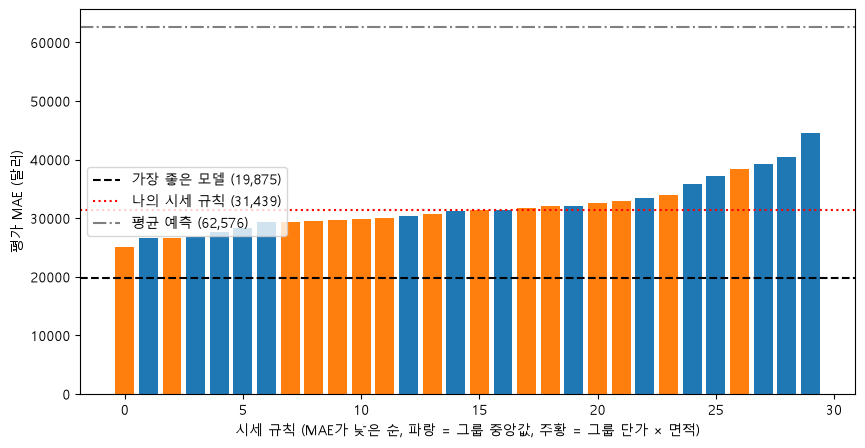

In [117]:
# [제공] 모델과 나의 시세 규칙의 위치
_log = pd.DataFrame(experiment_log)
_models = _log[_log["학습 MAE"].notna()]
_best = _models.sort_values("평가 MAE", kind="stable").iloc[0]
best_mae = float(_best["평가 MAE"])
my_mae = float(m_rule["MAE"])

print(f"가장 좋은 모델 [{_best['실험']}] 평가 MAE {best_mae:,.0f}")
print(f"  MAE로 이기는 시세 규칙: {(rules['평가 MAE'] > best_mae).sum()}개 / {len(rules)}개")
print(f"나의 시세 규칙 [{my_rule_text}] 평가 MAE {my_mae:,.0f}")
print(f"  30개 중 나보다 MAE가 낮은 시세 규칙: {(rules['평가 MAE'] < my_mae).sum()}개")
print()
print("정보 수 × 계산법별 MAE 중앙값")
print(rules.pivot_table(index="정보 수", columns="계산법", values="평가 MAE", aggfunc="median").round(0))

fig, ax = plt.subplots(figsize=(10, 5))
colors = rules["계산법"].map({"(가) 그룹 중앙값": "tab:blue", "(나) 그룹 단가 × 면적": "tab:orange"})
ax.bar(range(len(rules)), rules["평가 MAE"], color=colors)
ax.axhline(best_mae, color="black", linestyle="--", label=f"가장 좋은 모델 ({best_mae:,.0f})")
ax.axhline(my_mae, color="red", linestyle=":", label=f"나의 시세 규칙 ({my_mae:,.0f})")
ax.axhline(m_mean["MAE"], color="gray", linestyle="-.", label=f"평균 예측 ({m_mean['MAE']:,.0f})")
ax.set_xlabel("시세 규칙 (MAE가 낮은 순, 파랑 = 그룹 중앙값, 주황 = 그룹 단가 × 면적)")
ax.set_ylabel("평가 MAE (달러)")
ax.legend(loc="center left")
plt.show()

## 5-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: 상당히 비슷했다 그런데 임의의 시세 규칙에 비해서 예상보다도 상당히 낮았다. 

> **[판단]** 정보를 1개 쓴 규칙과 2개 쓴 규칙, 계산법 (가)와 (나) 중 어느 쪽의 MAE가 대체로 낮은가요? 계산법 (나)가 유리하거나 불리한 경우는 어떤 정보를 쓸 때인지도 표에서 찾아 보세요.
>
> 나의 답: 정보 2개가 1개보다 중앙값 MAE가 낮았다(1개 32,983~39,265달러, 2개 29,749~30,329달러). 계산법은 (나) 단가 × 면적이 두 경우 모두 조금 낮았다.

> **[판단]** 가장 좋은 시세 규칙과 가장 좋은 모델의 MAE 차이는 얼마인가요? 이 차이와, 시세 규칙은 누구나 이해하고 바로 쓸 수 있다는 점을 함께 놓고 보면 기획팀에 무엇을 권하겠습니까?
>
> 나의 답: 가장 좋은 시세 규칙(25,031달러)과 가장 좋은 모델(19,875달러)의 MAE 차이는 약 5,200달러(20.6%)다. 기획팀에는 모델을 기본 시세로 도입하되, 이해하기 쉬운 시세 규칙은 설명용과 백업으로 병행하고, 고가 매물은 담당자가 검토하도록 권하겠다.

> **[판단]** 나의 시세 규칙은 30개 사이에서 어디쯤인가요? 정보를 하나 더하거나 계산법을 바꾼다면 어떤 규칙을 고르겠습니까? 위 표에서 그 규칙을 찾아 결과를 적어 보세요.
>
> 나의 답: 원래 규칙(동네 단가 × 면적, 31,439달러)은 30개 중 16개보다 MAE가 낮아 중간 아래쪽이다. 나를 포함한 31개 중 17위다. 원래 규칙과 가장 가까운 것은 동네 + 면적 구간, (나) 단가 × 면적(26,712달러, 3위)이다. 면적을 연속값 대신 구간으로 묶은 것만 다르다. 정보는 2개로 같다.

## 5-8. 기획팀 보고 메모

분석 결과를 기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **오차를 어떤 지표로 말할 것인가**: MAE와 RMSE 중 하나를 고르고, 의뢰서의 문장("너무 다르면 플랫폼을 믿지 않게 된다")에 근거해 이유를 쓴다. "평균적으로 ±얼마"를 달러로 적는다.
2. **지금 쓰는 방법(내 시세 규칙)과 비교해 얼마나 나은가**
3. **믿어도 되는 집과 믿으면 안 되는 집**: 5-1의 가격대별 오차에 근거해 구분 기준을 제안한다.
4. **주의할 점**: 1-4의 빈 값 처리 결정, 데이터의 한계(Ames 한 도시의 2006~2010년 거래), 아직 확인하지 못한 것

> **[판단]** 기획팀 보고 메모:
>
> 1. 오차 지표와 ±얼마: MAE를 쓴다. 최고 모델은 평균적으로 약 19,900달러 차이 난다.
>
> 2. 시세 규칙과의 비교: 내 규칙(27,599달러)보다 약 28% 낮고, 가장 좋은 시세 규칙(25,031달러)보다도 약 21% 낮다.
>
> 3. 믿어도 되는 집 / 믿으면 안 되는 집: 10만~20만 달러 구간은 모델 MAE가 약 13,400달러로 낮아 믿을 만하다. 30만 달러 이상의 고가 매물은 오차가 커서 자동 시세 대신 담당자가 검토하도록 한다.
>
> 4. 주의할 점: 빈 값을 "None"과 0으로 채운 처리 방식, 2006~2010년 한 도시(Ames) 데이터라는 한계, 고가 구간 표본이 적다는 점(30만 달러 이상은 24채 안팎)을 함께 적는다.

---
# 마무리

## 이 Chapter의 판단 포인트

> **MAE와 RMSE 중 무엇을 보고서에 쓸 것인가? 큰 오차를 얼마나 아프게 볼지는 지표가 아니라 비즈니스가 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "회귀 모델의 오차를 보면 평균 예측과 현행 시세 규칙의 오차를 먼저 찾는다."

> **[판단]** 나의 체크리스트 2번(회귀 지표를 볼 때):
>
> 나의 답: 회귀 점수는 MAE로 "평균적으로 얼마나 틀리는지"를 먼저 보고, 큰 오차를 특히 경계할 때는 RMSE를 함께 보며, 시세처럼 비율이 중요한 경우에는 MAPE를, 모델이 평균 예측보다 얼마나 나은지 볼 때는 R²를 본다.

> **[판단]** 나의 체크리스트 3번(학습용 점수와 평가용 점수를 볼 때):
>
> 나의 답: 두 점수의 차이를 확인 후 과적합 여부를 따져서 상황에 맞게 정규화를 적용한다.

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 3에서는 확률을 예측하는 **분류**를 배웁니다.